In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

import pandas as pd
import os
import glob

import xarray as xr
import numpy as np
from pyhomogenize import open_xrdataset
import matplotlib as mpl
import matplotlib.pyplot as plt

In [3]:
def directory_available(dir):
    if not os.path.exists(dir):
        os.makedirs(dir)
    return

In [4]:
home=os.getcwd()
# The data is quite large, therefore I use my work
database='/work/ch0636/g300047/cicles/'

In [5]:
# set directories

datadir=database +'/climate_fact_data/'
tmpdir=database+'/tmp/'
plotdir=database+'/horizontal-plots-test/'

In [20]:
directory_available(tmpdir)
directory_available(plotdir)

In [ ]:
# Define the data directory and variable
datadir = "/work/ch0636/g300047/cicles/climate_fact_data_tmp/results/20250224_TS_hori_afr22/"
var = "TG_year_"
timefreq = "_time-mean_ensemble-diff-median.nc"
what_rcp26 = "rcp26"
what_rcp85 = "rcp85"

# Get the list of files
sims_rcp26 = glob.glob(datadir + var + '*' + what_rcp26 + timefreq)
sims_rcp85 = glob.glob(datadir + var + '*' + what_rcp85 + timefreq)

# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp85.sort()

In [16]:
sims_rcp85

['/work/ch0636/g300047/cicles/climate_fact_data_tmp/results/20250224_TS_hori_afr22/TG_year_2011_2040_rcp85_time-mean_ensemble-diff-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data_tmp/results/20250224_TS_hori_afr22/TG_year_2041_2070_rcp85_time-mean_ensemble-diff-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data_tmp/results/20250224_TS_hori_afr22/TG_year_2071_2100_rcp85_time-mean_ensemble-diff-median.nc']

In [6]:
data = xr.open_dataset(datadir+'/results/20250312_TS_hori_afr22/TR_year_2069_2098_rcp85_time-mean.nc')
data
#data_variable = data['TG']
#data_variable.plot()

/tmp/ipykernel_1880611/407435810.py:1: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  data = xr.open_dataset(datadir+'/results/20250312_TS_hori_afr22/TR_year_2069_2098_rcp85_time-mean.nc')


<xarray.Dataset> Size: 14MB
Dimensions:      (realization: 9, rlon: 388, rlat: 402)
Coordinates:
    height       float64 8B ...
  * realization  (realization) <U96 3kB 'AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_...
  * rlon         (rlon) float64 3kB -24.75 -24.53 -24.31 ... 59.95 60.17 60.39
  * rlat         (rlat) float64 3kB -45.87 -45.65 -45.43 ... 41.91 42.13 42.35
    lon          (rlat, rlon) float64 1MB ...
    lat          (rlat, rlon) float64 1MB ...
Data variables:
    TR           (realization, rlat, rlon) timedelta64[ns] 11MB ...

In [36]:
#Temperature
level_steps_diff=[-0.5,0,0.5,1,1.5,2,2.5,3,3.5,4,4.5,5,5.5,6]
#level_steps=[0,1,30,60,90,120,150,180,210,240,270,300]
#level_steps=[0,10,12,16,20,24,28,32,36,40,44,48]
#colors_absolute=['#ffffff','#ffffcc','#ffeda0','#fed976','#feb24c','#fd8d3c','#fc4e2a','#e31a1c','#bd0026','#800026']
color_steps=["#FFFFFF","#FFFF00","#FFD700","#FFA500","#FF8C00","#FF4500","#FF0000","#8B0000","#800000","#4B0082"]
#level_steps_diff=[-200,-150,-100,-50,-10,0,10,50,100,150,200]
#color_steps_diff=["#FFFFFF","#FFFF00","#FFD700","#FFA500","#FF8C00","#FF4500","#FF0000","#8B0000","#800000","#4B0082"]
color_steps_diff=['#313695','#4575b4','#74add1','#abd9e9','#e0f3f8','#ffffbf','#fee090','#fdae61','#f46d43','#d73027','#a50026','#67000d','#49006a']

In [26]:
import matplotlib
font = {
    'family' : 'sans-serif',
    'weight' : 'normal',
}

# haesslich:'monospace', 'serif'
# sehe den Unterschied nicht: 'fantasy','sans', 'sans serif', 'sans-serif'
matplotlib.rc('font', **font)

def plot_6(
    ds_dict,
    var="",
    robustness=None,
    ts="",
    exp="",
    mode="absolut",
    add_cbar = True,
    hatchcolor="k",
    extend="neither",
):
    if mode == "absolut":
        levels=level_steps
        colors=color_steps
        vmin=0.00001
    elif mode == "diff":
        levels=level_steps_diff
        colors=color_steps
        vmin=-200 # macht keinen sinn
    else:
        print("Mode {} not known! Use 'absolut' or 'diff'")
        return

    import matplotlib.pyplot as plt
    import cordex
    import numpy as np
    from cartopy import crs as ccrs
    import cartopy.feature as cf
    
    cordex_grid = cordex.cordex_domain("AFR-22", add_vertices=True)
    #rotated_lat_lon = cordex_grid.rotated_latitude_longitude
    #pole = (rotated_lat_lon.grid_north_pole_longitude, rotated_lat_lon.grid_north_pole_latitude)
    #projection = ccrs.RotatedPole(*pole)
    
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(
        ncols=3, nrows=2, figsize=(19,13),
    )
    axes = (ax1, ax2, ax3, ax4, ax5, ax6)
    pos = .05
    

    
    for ax in axes:
        ax.gridlines(
            draw_labels={"bottom": "x", "left": "y"}, 
            dms=True,
            x_inline=False, 
            y_inline=False,
            linewidth=0.5,
        )
        ax.coastlines(resolution="50m", color="black", linewidth=1)
        ax.add_feature(cf.BORDERS)
        ax.set_extent([-22,10,-16,21])
        
    for expts, ax in zip(ds_dict, axes):
        im = ds_dict[expts][var].plot(
            ax=ax,
            levels=levels,
            colors=colors,
            transform=projection,
            extend=extend,
            add_colorbar=False,
            alpha=.8,
        )
        if robustness is True:
            rob_sel = ds_dict[expts]["robustness"]
            plt.rcParams.update({'hatch.color': hatchcolor})
            rob_sel = rob_sel.squeeze()
            significant = xr.where(rob_sel != 0, 1, 0).squeeze()
            significant.plot.contourf(
                ax=ax,
                levels=[-.5,.5],
                colors='none',
                hatches=[None, None, "//", "//"],
                add_colorbar=False,
                extend='both',
                transform=projection,
            )
        exp = expts.split("_")[0]
        ts = expts.split("_")[1]
        s = "Mean change of snow cover duration \n Annual ({}), {}".format(exp, ts)
        ax.set_title(s+": ", fontdict={"fontsize": 15})
        
    #fig.suptitle("Ensemble mean snow cover duration (November - April)", y=0.92,fontsize=25)
    if add_cbar is True:
        cbar_ax = fig.add_axes([0.15, pos, 0.7, 0.03])
        fig.colorbar(im, cax=cbar_ax, orientation="horizontal", label='[ days / year ]')
    
    savefig(plt, "{}/ensemble_mean_diff_snowcoverduration_all_oT_YlGrBl.png".format(output_path))
    return plt  

NameError: name 'regridder' is not defined

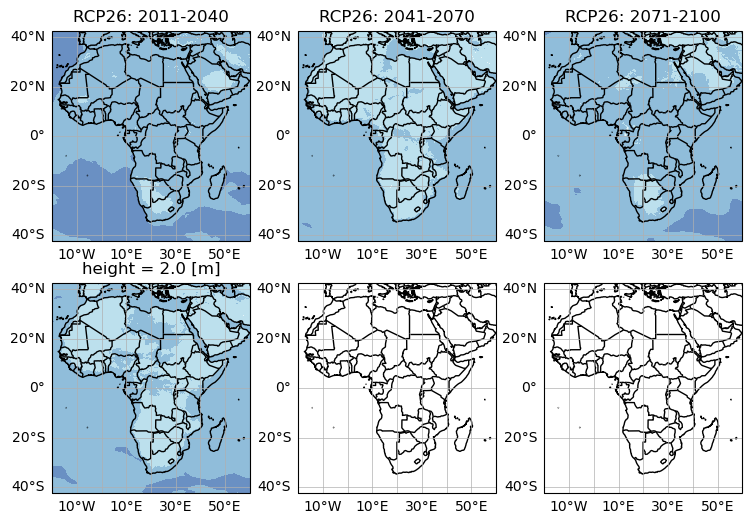

In [43]:
import matplotlib
font = {
    'family' : 'sans-serif',
    'weight' : 'normal',
}
matplotlib.rc('font', **font)

levels=level_steps_diff
colors=color_steps_diff

vmin=0.00001
import matplotlib.pyplot as plt
import cordex
import numpy as np
from cartopy import crs as ccrs
import cartopy.feature as cf
    
extend="neither"

# Create subplots
fig, axes = plt.subplots(
        ncols=3, nrows=2, figsize=(9,6), subplot_kw={'projection': ccrs.PlateCarree()}) 
pos = .05
    
for row in axes:
    for ax in row:
        ax.gridlines(
            draw_labels={"bottom": "x", "left": "y"}, 
            dms=True,
            x_inline=False, 
            y_inline=False,
            linewidth=0.5,
        )
        ax.coastlines(resolution="50m", color="black", linewidth=1)
        ax.add_feature(cf.BORDERS)
        ax.set_extent([-20,60,-35,35])


# Plot data for rcp26
for i, file in enumerate(sims_rcp26):
    data = xr.open_dataset(file)
    data_variable = data['TG']
    im = data_variable.plot(ax=axes[0, i],
                            levels=levels,
                            colors=colors,
                            transform=ccrs.PlateCarree(),
                            extend=extend,
                            add_colorbar=False,
                            alpha=.8,
                            )
    axes[0, i].set_title(f'RCP26: {file.split("_")[8]}-{file.split("_")[9]}')

# Plot data for rcp85
for i, file in enumerate(sims_rcp85):
    data = xr.open_dataset(file)
    #print(i)
    data_variable = data['TG']
    im = data_variable.plot(ax=axes[1, i],
                       levels=levels,
                       colors=colors,
                       transform=ccrs.PlateCarree(),
                       extend=extend,
                       add_colorbar=False,
                       alpha=.8,
                       )
    
    rob_sel = regridder(robustness)
    plt.rcParams.update({'hatch.color': hatchcolor})
    rob_sel = rob_sel.squeeze()
    rob = rob_sel.sel({col: c})
    significant = xr.where(rob != 0, 1, 0).squeeze()
    significant.plot.contourf(
        ax=ax,
        levels=[-.5,.5],
        colors='none',
        hatches=[None, None, "//", "//"],
        add_colorbar=False,
        extend='both',
        transform=projection,
    )
    axes[1, i].set_title(f'RCP85: {file.split("_")[8]}-{file.split("_")[9]}')
#
exp='annual'
ts='temperature'
s = "Median of mean changes in {} {}".format(exp, ts)
fig.suptitle(s+": ", fontsize=15)
cbar_ax = fig.add_axes([0.15, -0.02, 0.7, 0.03])
fig.colorbar(im, cax=cbar_ax, orientation="horizontal", label='[ K ]')
plt.tight_layout()
plt.show()

In [84]:
def savefig(plot, name):
    plot.savefig(name, dpi=300)

In [ ]:
import matplotlib
font = {
    'family' : 'sans-serif',
    'weight' : 'normal',
}

# haesslich:'monospace', 'serif'
# sehe den Unterschied nicht: 'fantasy','sans', 'sans serif', 'sans-serif'
matplotlib.rc('font', **font)

def plot_9(
    ds_dict,
    var="",
    robustness=None,
    ts="",
    exp="",
    mode="absolut",
    add_cbar = True,
    hatchcolor="k",
    extend="neither",
):
    if mode == "absolut":
        levels=level_steps
        colors=color_steps
    elif mode == "diff":
        levels=diff_category[var]
        colors=diff_colors[var]
    else:
        print("Mode {} not known! Use 'absolut' or 'diff'")
        return

    import matplotlib.pyplot as plt
    import cordex
    import numpy as np
    from cartopy import crs as ccrs
    import cartopy.feature as cf
    
    cordex_grid = cordex.cordex_domain("EUR-11", add_vertices=True)
    rotated_lat_lon = cordex_grid.rotated_latitude_longitude
    pole = (rotated_lat_lon.grid_north_pole_longitude, rotated_lat_lon.grid_north_pole_latitude)
    projection = ccrs.RotatedPole(*pole)
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9)) = plt.subplots(
        ncols=3, nrows=3, subplot_kw={"projection": projection}, figsize=(20,20),
    )
    axes = (ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9)
    pos = .05
    for ax in axes:
        ax.gridlines(
            draw_labels={"bottom": "x", "left": "y"}, 
            dms=True,
            x_inline=False, 
            y_inline=False,
            linewidth=0.5,
        )
        ax.coastlines(resolution="50m", color="black", linewidth=1)
        ax.add_feature(cf.BORDERS)
        ax.set_extent([-22,10,-16,21])
        
    for expts, ax in zip(ds_dict, axes):
        im = ds_dict[expts][var].plot(
            ax=ax,
            levels=levels,
            colors=colors,
            transform=projection,
            extend=extend,
            add_colorbar=False,
            #alpha=.8,
        )
        if not robustness is None:
            rob_sel = regridder(robustness)
            plt.rcParams.update({'hatch.color': hatchcolor})
            rob_sel = rob_sel.squeeze()
            rob = rob_sel.sel({col: c})
            significant = xr.where(rob != 0, 1, 0).squeeze()
            significant.plot.contourf(
                ax=ax,
                levels=[-.5,.5],
                colors='none',
                hatches=[None, None, "//", "//"],
                add_colorbar=False,
                extend='both',
                transform=projection,
            )
        exp = expts.split("_")[0]
        ts = expts.split("_")[1]
        s = "{}, {}".format(exp, ts)
        ax.set_title(s+": ", fontdict={"fontsize": 15})
    #fig.suptitle("Ensemble mean snow cover duration (November - April)", y=0.92,fontsize=25)
    if add_cbar is True:
        #cbar.set_label("Values - how2matplotlib.com", fontsize=16)
        cbar_ax = fig.add_axes([0.15, pos, 0.7, 0.03])
        fig.colorbar(im, cax=cbar_ax, orientation="horizontal", label='[ days / year ]')
    
    savefig(plt, "{}/ensemble_mean_snowcoverduration_all_oTT.png".format(output_path))
    return plt  